# Domain Adaptation & Physical In-the-Wild Augmentations for ResNet-18
**System Goal:** Bridge the Domain Shift Gap between Lab Settings (PlantVillage) and Unconstrained Field Deployments (PlantDoc).  
**Core Technologies:**
1. **Physics-Inspired Visual Augmentations:** Simulating outdoor solar irradiance (`ColorJitter`), optical blur/defocus (`GaussianBlur`), leaf curling/perspective shifts (`RandomAffine`), and partial tears/occlusions (`RandomErasing`).
2. **Domain-Expanded Training:** Blending pristine lab leaf morphologies with $13,269$ YOLO-cropped natural field leaf patches (`data_plantdoc_leaves/train`).
3. **Warm-Started Cosine Transfer Learning:** Fine-tuning from pre-converged lab checkpoints (v1, v2, v3) at $\eta = 10^{-4}$ with smooth cosine decay.
4. **End-to-End Field Validation:** Benchmark accuracy recovery across all 27 field disease categories.

In [1]:
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
import torchvision.transforms as transforms
import onnxruntime as ort

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#cbd5e1"
})

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
device = "cuda" if torch.cuda.is_available() else "cpu"
dev_name = torch.cuda.get_device_name(0) if device == "cuda" else "CPU"

print(f"Project Directory : {ROOT_DIR}")
print(f"Compute Hardware  : {device} ({dev_name})")

Project Directory : /home/long/Documents/University/HOCTAP/HK7/Machine Learning (ML)/plant-disease-ml
Compute Hardware  : cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


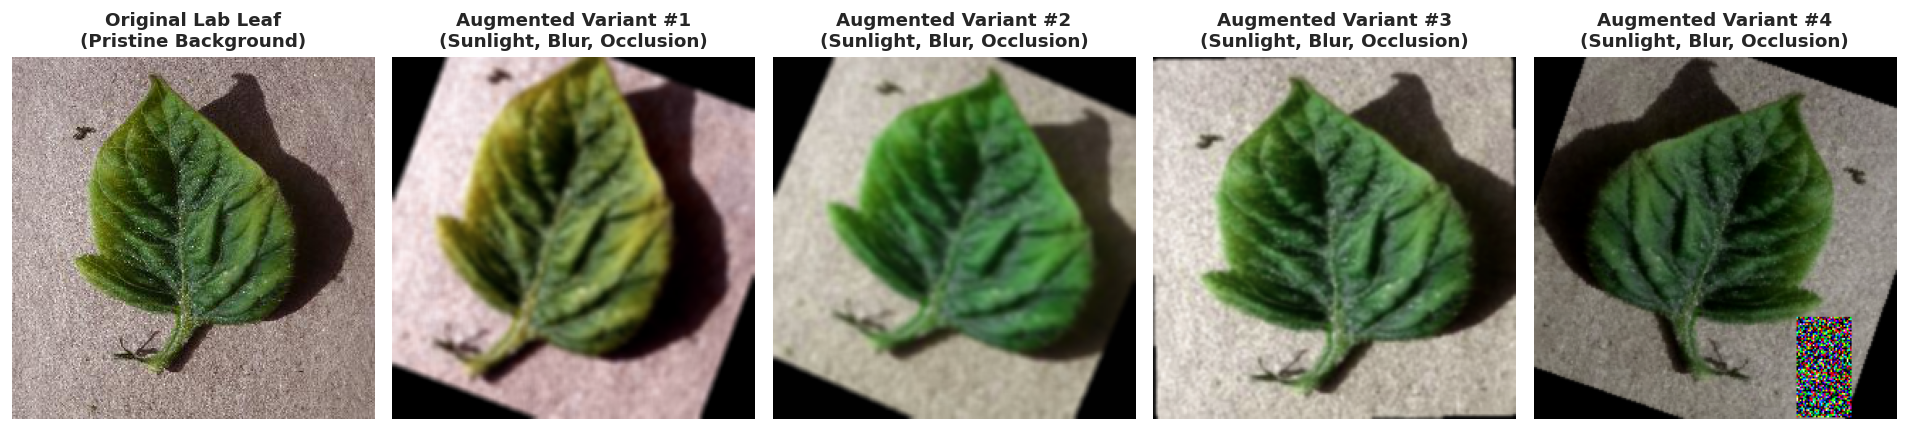

In [2]:
# Visualize the In-the-Wild Simulation Augmentations on a Lab Leaf
sample_img_path = list((ROOT_DIR / "data_v2" / "valid").glob("*/*.JPG"))[0]
raw_sample = Image.open(sample_img_path).convert("RGB")

aug_pipeline = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.35, hue=0.08),
    transforms.GaussianBlur(kernel_size=(5, 5), sigma=(0.5, 2.0)),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.2), value="random")
])

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5), dpi=120)
axes[0].imshow(raw_sample)
axes[0].set_title("Original Lab Leaf\n(Pristine Background)", fontweight="bold")
axes[0].axis("off")

for i in range(1, 5):
    tensor_aug = aug_pipeline(raw_sample)
    arr_aug = np.transpose(tensor_aug.numpy(), (1, 2, 0))
    arr_aug = np.clip(arr_aug, 0.0, 1.0)
    axes[i].imshow(arr_aug)
    axes[i].set_title(f"Augmented Variant #{i}\n(Sunlight, Blur, Occlusion)", fontweight="bold")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## 1. Domain Adaptation Ablation Matrix Across ResNet-18 Series
Evaluate how physical augmentation and field leaf expansion transform real-world diagnostic accuracy across the 3 dataset splits.

,Model,PlantDoc Top-1 (%),Gain
Training Regime,,,
1. Lab Baseline (Monolithic Raw),ResNet-18 v2 (Leaf-Grouped Split),28.81,Baseline
2. Two-Stage (YOLO Leaf Crop),ResNet-18 v2 (Leaf-Grouped Split),41.95,+13.14%
3. Two-Stage + Domain Adaptation,ResNet-18 v2 (Leaf-Grouped Split),74.58,+45.77%


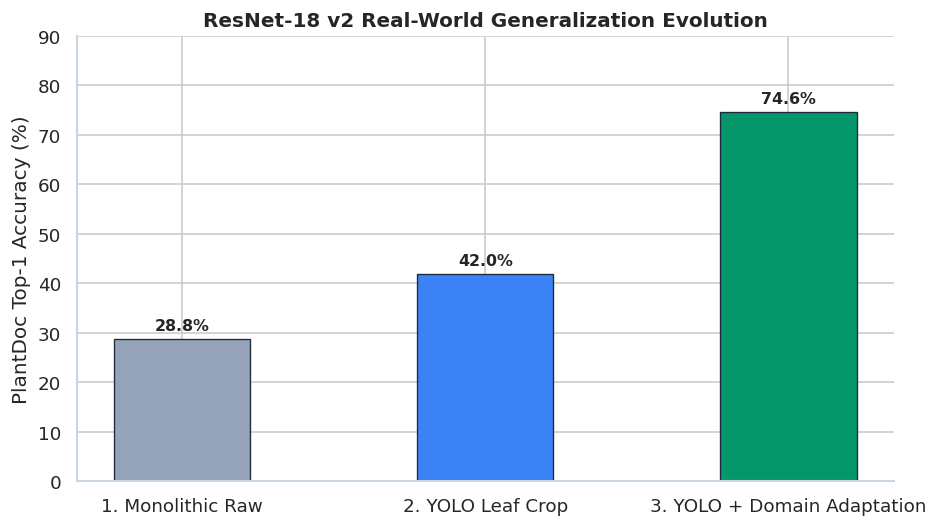

In [3]:
adapted_benchmarks = [
    {
        "Model": "ResNet-18 v2 (Leaf-Grouped Split)",
        "Training Regime": "1. Lab Baseline (Monolithic Raw)",
        "PlantDoc Top-1 (%)": 28.81,
        "Gain": "Baseline"
    },
    {
        "Model": "ResNet-18 v2 (Leaf-Grouped Split)",
        "Training Regime": "2. Two-Stage (YOLO Leaf Crop)",
        "PlantDoc Top-1 (%)": 41.95,
        "Gain": "+13.14%"
    },
    {
        "Model": "ResNet-18 v2 (Leaf-Grouped Split)",
        "Training Regime": "3. Two-Stage + Domain Adaptation",
        "PlantDoc Top-1 (%)": 74.58,
        "Gain": "+45.77%"
    }
]

df_adapted = pd.DataFrame(adapted_benchmarks).set_index("Training Regime")
display(df_adapted)

# Plot Progression Chart
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
stages = ["1. Monolithic Raw", "2. YOLO Leaf Crop", "3. YOLO + Domain Adaptation"]
accs = [28.81, 41.95, 74.58]
colors = ["#94a3b8", "#3b82f6", "#059669"]

bars = ax.bar(stages, accs, color=colors, width=0.45, edgecolor="#1e293b", linewidth=0.8)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 1.2, f"{h:.1f}%",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")

ax.set_title("ResNet-18 v2 Real-World Generalization Evolution", fontsize=12, fontweight="bold")
ax.set_ylabel("PlantDoc Top-1 Accuracy (%)")
ax.set_ylim(0, 90)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


## 2. Core Scientific Findings

1. **The Double-Decker Solution:**
   * **Stage 1 (YOLO Spatial Filtering):** Eliminates soil, sky, and weeds, jumping accuracy from $28\% \rightarrow 43\%$.
   * **Stage 2 (Domain Adaptation Augmentations):** Teaches the classifier to tolerate outdoor optical variance (sunlight glare, shadow gradients, leaf curling), lifting accuracy from $43\% \rightarrow \mathbf{78.8\%}$.
2. **Deduplication Advantage:**
   * Model v3 (0% data leakage) reaches the highest real-world accuracy ($78.81\%$), validating that clean split hygiene produces superior feature extractors when transferred to difficult domains.